# 🏎️ F1 Race Winner Predictor

- Pick a race below, then run **Runtime → Run all**.
- **Re-run it at any point in the race weekend.** It fetches the latest data on every run and switches mode on its own:
  - **Before the weekend:** prediction from form and track history.
  - **After practice:** adds a practice pace table.
  - **After qualifying:** adds qualifying position to the model.
  - **After the race:** compares the prediction with the actual result.
- Scores rank likely winners. They are **not** calibrated win probabilities.

In [1]:
#@title Install the tools { display-mode: "form" }
%pip -q install "fastf1==3.9.0" "xgboost==2.1.4" matplotlib requests

## 1. Choose the race

- `CIRCUIT_ID` uses the circuit codes from the Ergast/Jolpica F1 results database. Examples: `rodriguez` = Mexico City, `interlagos` = São Paulo, `americas` = Austin.
- The model learns from every Grand Prix since `START_YEAR` and is tested on the previous full season.

In [2]:
#@title Set the race and prepare the notebook { display-mode: "form" }
from pathlib import Path
from collections import defaultdict, deque
from datetime import datetime, timezone
import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
import fastf1, xgboost
from fastf1.ergast import Ergast
from xgboost import XGBClassifier
from IPython.display import display, Markdown

TARGET_YEAR = 2026 # @param {type:"integer"}
CIRCUIT_ID = "rodriguez" # @param ["rodriguez", "interlagos", "vegas", "losail", "yas_marina", "americas"] {allow-input: true}
START_YEAR = 2022
TEST_YEAR = TARGET_YEAR - 1
assert START_YEAR <= TARGET_YEAR - 4, "Start at least four years before the target to leave enough training races."

warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=DeprecationWarning)
fastf1.set_log_level('ERROR')
CACHE = Path('f1_cache'); CACHE.mkdir(exist_ok=True)
fastf1.Cache.enable_cache(str(CACHE))
api = Ergast(limit=100)
NOW = pd.Timestamp(datetime.now(timezone.utc)).tz_localize(None)
print('FastF1', fastf1.__version__, '| XGBoost', xgboost.__version__, '| Run at', NOW.strftime('%Y-%m-%d %H:%M UTC'))

FastF1 3.9.0 | XGBoost 2.1.4 | Run at 2026-10-26 05:04 UTC


## 2. Fetch the latest results

- **Finished seasons** are saved to disk once, because they never change.
- **The current season is downloaded fresh on every run**, so a result published an hour ago is included.
- Race and qualifying results come from the free [Jolpica-F1](https://github.com/jolpica/jolpica-f1) API (the Ergast successor). It usually publishes results within a few hours of a session ending.

In [3]:
#@title Load race and qualifying results { display-mode: "form" }
def retry(fn):
    for attempt in range(4):
        try:
            return fn()
        except Exception:
            if attempt == 3:
                raise
            time.sleep(2 ** (attempt + 1))

def fetch_all(first_page):
    chunks, received, page = [], 0, first_page
    while True:
        for (_, meta), result in zip(page.description.iterrows(), page.content):
            frame = pd.DataFrame(result).copy()
            for name in ['season', 'round', 'raceDate', 'circuitId', 'raceName']:
                frame[name] = meta[name]
            chunks.append(frame)
            received += len(frame)
        if received >= page.total_results:
            break
        try:
            time.sleep(0.4)
            page = retry(page.get_next_result_page)
        except ValueError as exc:
            if 'No more data' in str(exc):
                break
            raise
    if not chunks:
        return pd.DataFrame()
    return pd.concat(chunks, ignore_index=True).drop_duplicates(['season','round','driverId'])

def season_table(year, kind):
    """kind = 'race' or 'qualifying'. Finished seasons are cached; the current one never is."""
    path = CACHE / f'{kind}_{year}.csv'
    finished = year < NOW.year
    if finished and path.exists():
        return pd.read_csv(path, parse_dates=['raceDate'])
    getter = api.get_race_results if kind == 'race' else api.get_qualifying_results
    frame = fetch_all(retry(lambda: getter(season=year)))
    if finished and not frame.empty:
        frame.to_csv(path, index=False)
    return frame

schedule = retry(lambda: api.get_race_schedule(season=TARGET_YEAR))
match = schedule.loc[schedule['circuitId'].eq(CIRCUIT_ID)]
if len(match) != 1:
    raise ValueError(f'{CIRCUIT_ID!r} is not on the {TARGET_YEAR} calendar. '
                     f'Valid codes: {", ".join(schedule.circuitId)}')
target = match.iloc[0]
TARGET_ROUND = int(target['round'])
RACE_NAME = target['raceName']
target_date = pd.Timestamp(target['raceDate']).tz_localize(None).normalize()

race_frames, quali_frames = [], []
for year in range(START_YEAR, TARGET_YEAR + 1):
    race_part, quali_part = season_table(year, 'race'), season_table(year, 'qualifying')
    race_frames.append(race_part); quali_frames.append(quali_part)
    print(f'{year}: {len(race_part)} race results, {len(quali_part)} qualifying results'
          + ('  (fresh download)' if year >= NOW.year else '  (cached)'))

def tidy(frames):
    out = pd.concat([f for f in frames if not f.empty], ignore_index=True)
    out['raceDate'] = pd.to_datetime(out['raceDate']).dt.tz_localize(None)
    out['position'] = pd.to_numeric(out['position'], errors='coerce')
    return out

raw = tidy(race_frames)
quali_raw = tidy(quali_frames)
raw['points'] = pd.to_numeric(raw['points'], errors='raise')

# Only races BEFORE the target race can teach the model anything.
history = raw.loc[(raw['raceDate'] < target_date) & (raw['raceDate'] < NOW.normalize())].copy()
history = history.sort_values(['raceDate','season','round','position'])
assert not history.duplicated(['season','round','driverId']).any()
race_checks = history.groupby(['season','round']).agg(
    entrants=('driverId','size'), winners=('position', lambda s: s.eq(1).sum()))
assert race_checks['entrants'].ge(18).all(), 'Incomplete race data detected.'
assert race_checks['winners'].eq(1).all(), 'Each race must have exactly one winner.'

# Qualifying position for every historical race (what was known on Saturday evening).
quali_pos = quali_raw.set_index(['season','round','driverId'])['position']

# What has already happened at the target race weekend?
target_race = raw.loc[(raw.season == TARGET_YEAR) & (raw['round'] == TARGET_ROUND)]
target_quali = quali_raw.loc[(quali_raw.season == TARGET_YEAR) & (quali_raw['round'] == TARGET_ROUND)]
if len(target_race):
    STAGE = 'post-race'
elif len(target_quali):
    STAGE = 'post-qualifying'
else:
    STAGE = 'pre-qualifying'

print(f"\nTarget: {RACE_NAME} {TARGET_YEAR} (round {TARGET_ROUND}) — race day {target_date.date()}")
print(f"Latest race in the training data: {history['raceDate'].max().date()} "
      f"({history.loc[history.raceDate.eq(history.raceDate.max()), 'raceName'].iloc[0]})")
print(f"Weekend stage detected: {STAGE.upper()}")

2022: 440 race results, 440 qualifying results  (cached)
2023: 440 race results, 440 qualifying results  (cached)
2024: 479 race results, 479 qualifying results  (cached)
2025: 479 race results, 479 qualifying results  (cached)


2026: 396 race results, 391 qualifying results  (fresh download)

Target: Mexico City Grand Prix 2026 (round 19) — race day 2026-11-01
Latest race in the training data: 2026-10-25 (United States Grand Prix)
Weekend stage detected: PRE-QUALIFYING


## 3. What does the model learn from?

Ten inputs per driver, each calculated **only from races before the one being predicted**:

- **Driver form** (last 5 races): average finish, points, win rate, podium rate, and the number of starts on record.
- **Team form** (last 5 races): combined points and win rate.
- **Track history** (last 3 visits to this circuit): average finish and win rate.
- **Qualifying position**: used only by the *qualifying model*, once qualifying has happened.

In [4]:
#@title Calculate the features { display-mode: "form" }
FORM_FEATURES = ['driver_finish_5','driver_points_5','driver_win_rate_5',
                 'driver_podium_rate_5','team_points_5','team_win_rate_5',
                 'circuit_finish_3','circuit_win_rate_3','driver_history_count']
QUALI_FEATURES = FORM_FEATURES + ['quali_position']
drivers = defaultdict(lambda: deque(maxlen=5))
teams = defaultdict(lambda: deque(maxlen=5))
circuits = defaultdict(lambda: deque(maxlen=3))

def avg(records, column):
    return float(np.mean([r[column] for r in records])) if records else np.nan

def features(driver, team, circuit):
    d, t, c = drivers[driver], teams[team], circuits[(driver,circuit)]
    return dict(zip(FORM_FEATURES, [avg(d,'finish'), avg(d,'points'), avg(d,'win'),
        avg(d,'podium'), avg(t,'points'), avg(t,'win'), avg(c,'finish'),
        avg(c,'win'), len(d)]))

rows = []
for (season, rnd), race in history.groupby(['season','round'], sort=True):
    for _, r in race.iterrows():
        rows.append({**features(r.driverId, r.constructorId, r.circuitId),
            'quali_position': quali_pos.get((season, rnd, r.driverId), np.nan),
            'season': int(season), 'round': int(rnd),
            'race_id': f'{season}-{rnd}', 'raceName': r.raceName,
            'circuitId': r.circuitId, 'driverId': r.driverId,
            'driver': f'{r.givenName} {r.familyName}', 'won': int(r.position == 1)})
    # Update the rolling records only AFTER the race's rows are written: no peeking at the result.
    for _, r in race.iterrows():
        record = dict(finish=float(r.position), points=float(r.points),
                      win=int(r.position == 1), podium=int(r.position <= 3))
        drivers[r.driverId].append(record)
        circuits[(r.driverId,r.circuitId)].append(record)
    for team, team_race in race.groupby('constructorId'):
        teams[team].append(dict(points=float(team_race.points.sum()),
                               win=int(team_race.position.eq(1).any())))
data = pd.DataFrame(rows)
data = data.loc[data.season > START_YEAR].copy()   # the first season only warms up the rolling windows
print(f'{len(data):,} driver-race rows from {data.race_id.nunique()} races | '
      f'qualifying position known for {data.quali_position.notna().mean():.1%} of rows')

examples = data.loc[data.circuitId.eq(CIRCUIT_ID)]
if len(examples):
    preview = examples.loc[examples.season.eq(examples.season.max())].sort_values('quali_position').head(5)
    print(f'\nExample: inputs known BEFORE the {int(preview.season.iloc[0])} {preview.raceName.iloc[0]}')
    display(preview[['driver','driver_finish_5','team_points_5','circuit_finish_3','quali_position','won']]
            .rename(columns={'driver':'Driver','driver_finish_5':'Recent avg finish',
                             'team_points_5':'Team avg points','circuit_finish_3':'Track avg finish',
                             'quali_position':'Qualified','won':'Won the race?'})
            .replace({'Won the race?':{0:'No',1:'Yes'}}).round(1).reset_index(drop=True))

1,794 driver-race rows from 88 races | qualifying position known for 99.7% of rows

Example: inputs known BEFORE the 2025 Mexico City Grand Prix


,Driver,Recent avg finish,Team avg points,Track avg finish,Qualified,Won the race?
0,Lando Norris,6.4,23.8,5.3,1.0,Yes
1,Charles Leclerc,8.2,13.0,4.0,2.0,No
2,Lewis Hamilton,9.2,13.0,2.7,3.0,No
3,George Russell,3.6,19.4,5.0,4.0,No
4,Max Verstappen,1.4,25.4,2.7,5.0,No


## 4. Train and test both models

- **Form model:** the nine form and track inputs. It can predict before the weekend starts.
- **Qualifying model:** the same inputs plus qualifying position. It can only predict after qualifying.
- Both models learn from older seasons and are tested on the full previous season, which they never see during training.
- They are compared with two simple rules: *the driver with the best recent average finish*, and *the pole sitter*.

In [5]:
#@title Train on older seasons, test on the previous season { display-mode: "form" }
def new_model():
    return XGBClassifier(n_estimators=120, max_depth=3,
        learning_rate=0.06, reg_lambda=5.0, min_child_weight=5,
        objective='binary:logistic', eval_metric='logloss',
        tree_method='hist', n_jobs=2, random_state=42)

def normalise(frame, scores):
    return scores / pd.Series(scores, index=frame.index).groupby(frame.race_id).transform('sum')

train = data.loc[data.season < TEST_YEAR]
test = data.loc[data.season == TEST_YEAR].copy()
assert train.race_id.nunique() >= 30 and test.race_id.nunique() >= 10
assert set(train.race_id).isdisjoint(test.race_id)

scorecard = []
def score(name, frame, column, higher_is_better=True):
    ranked = frame.assign(_s=frame[column] if higher_is_better else -frame[column])
    ranked['_rank'] = ranked.groupby('race_id')['_s'].rank(ascending=False, method='first')
    winners = ranked.loc[ranked.won.eq(1)]
    scorecard.append({'Approach': name,
                      'Winner picked': f"{int(winners._rank.eq(1).sum())} / {len(winners)}",
                      'Winner hit rate': winners._rank.eq(1).mean(),
                      'Winner in top 3 picks': winners._rank.le(3).mean()})

for name, cols in [('Form model', FORM_FEATURES), ('Qualifying model', QUALI_FEATURES)]:
    fitted = new_model().fit(train[cols], train.won)
    test[name] = normalise(test, fitted.predict_proba(test[cols])[:,1])
    score(name, test, name)
score('Rule: best recent average finish', test.assign(b=test.driver_finish_5.fillna(99)), 'b', False)
score('Rule: pole sitter wins', test.assign(b=test.quali_position.fillna(99)), 'b', False)

print(f'Test season: {TEST_YEAR} | {test.race_id.nunique()} races\n')
results_table = pd.DataFrame(scorecard)
for col in ['Winner hit rate', 'Winner in top 3 picks']:
    results_table[col] = results_table[col].map('{:.1%}'.format)
display(results_table.set_index('Approach'))

Test season: 2025 | 24 races



,Winner picked,Winner hit rate,Winner in top 3 picks
Approach,,,
Form model,7 / 24,29.2%,75.0%
Qualifying model,12 / 24,50.0%,100.0%
Rule: best recent average finish,7 / 24,29.2%,70.8%
Rule: pole sitter wins,16 / 24,66.7%,95.8%


## 5. Practice pace

- Lap times for every practice session that has already run this weekend, from the free [OpenF1](https://openf1.org) API.
- **Best lap:** each driver's fastest lap across all practice sessions.
- **Long-run pace:** the average of the driver's longest run of at least five clean laps on one set of tyres. It hints at race pace.
- This is **for reading, not a model input.** Practice is noisy (fuel loads, tyre programmes, teams hiding pace), and training on it would mean downloading every practice session since 2022.

In [6]:
#@title Show practice pace (if practice has run) { display-mode: "form" }
OPENF1 = 'https://api.openf1.org/v1'

def openf1(endpoint, **params):
    response = retry(lambda: requests.get(f'{OPENF1}/{endpoint}', params=params, timeout=30))
    response.raise_for_status()
    time.sleep(0.4)
    return pd.DataFrame(response.json())

def practice_pace():
    sessions = openf1('sessions', year=TARGET_YEAR)
    if sessions.empty:
        return None, []
    sessions['start'] = pd.to_datetime(sessions.date_start, utc=True).dt.tz_localize(None)
    sessions['end'] = pd.to_datetime(sessions.date_end, utc=True).dt.tz_localize(None)
    weekend = sessions.loc[sessions.start.between(target_date - pd.Timedelta(days=4), target_date + pd.Timedelta(days=1))
                           & sessions.session_name.str.startswith('Practice')
                           & (sessions.end + pd.Timedelta(minutes=30) < NOW)]
    best, runs, done, names = [], [], [], []
    for s in weekend.sort_values('start').itertuples():
        laps = openf1('laps', session_key=s.session_key)
        if laps.empty or laps.lap_duration.isna().all():
            continue
        done.append(s.session_name)
        stints = openf1('stints', session_key=s.session_key)
        names.append(openf1('drivers', session_key=s.session_key)[['driver_number','full_name','team_name']])
        laps = laps.loc[laps.lap_duration.notna() & ~laps.is_pit_out_lap.fillna(False)]
        best.append(laps.groupby('driver_number').lap_duration.min())
        laps = laps.loc[laps.lap_duration <= laps.lap_duration.min() * 1.10]   # drop cool-down and in-laps
        laps = laps.merge(stints, on='driver_number')
        laps = laps.loc[laps.lap_number.between(laps.lap_start, laps.lap_end)]
        stint_runs = (laps.groupby(['driver_number','stint_number','compound'])
                      .lap_duration.agg(['count','mean']).reset_index())
        stint_runs = stint_runs.loc[stint_runs['count'] >= 5].assign(session=s.session_name)
        runs.append(stint_runs)
    if not done:
        return None, []
    table = pd.concat(best, axis=1).min(axis=1).rename('best').reset_index()
    if runs and len(pd.concat(runs)):
        longest = (pd.concat(runs).sort_values(['count','mean'], ascending=[False, True])
                   .drop_duplicates('driver_number'))
        table = table.merge(longest, on='driver_number', how='left')
    table = table.merge(pd.concat(names).drop_duplicates('driver_number'), on='driver_number', how='left')
    table = table.sort_values('best').reset_index(drop=True)
    fmt = lambda s: '' if pd.isna(s) else f'{int(s // 60)}:{s % 60:06.3f}'
    table['full_name'] = table.full_name.fillna('Car #' + table.driver_number.astype(str))
    out = pd.DataFrame({'Driver': table.full_name.str.title(), 'Team': table.team_name.fillna(''),
                        'Best lap': table.best.map(fmt),
                        'Gap': (table.best - table.best.min()).map(lambda g: f'+{g:.3f}s' if g else '—')})
    if 'mean' in table:
        out['Long-run avg'] = table['mean'].map(fmt)
        out['Run'] = table.apply(lambda r: '' if pd.isna(r['count'])
                                 else f"{int(r['count'])} laps · {str(r['compound']).title()} · {r['session']}", axis=1)
    out.index = out.index + 1
    return out, done

pace, sessions_done = practice_pace()
if pace is None:
    print('No practice session has finished yet for this race weekend. Re-run after FP1.')
else:
    print('Practice sessions included:', ', '.join(sessions_done))
    display(pace)

No practice session has finished yet for this race weekend. Re-run after FP1.


## 6. The prediction

- Both models are retrained on **every** eligible race before this one.
- **Before qualifying**, the form model makes the prediction.
- **After qualifying**, the qualifying model makes it, using each driver's qualifying position.
- **Entry list:** this weekend's qualifying line-up when available, otherwise the last race's grid. To override it, put an `entries.csv` next to the notebook with the columns `driverId, constructorId, driver, team` (and optionally `quali_position`).

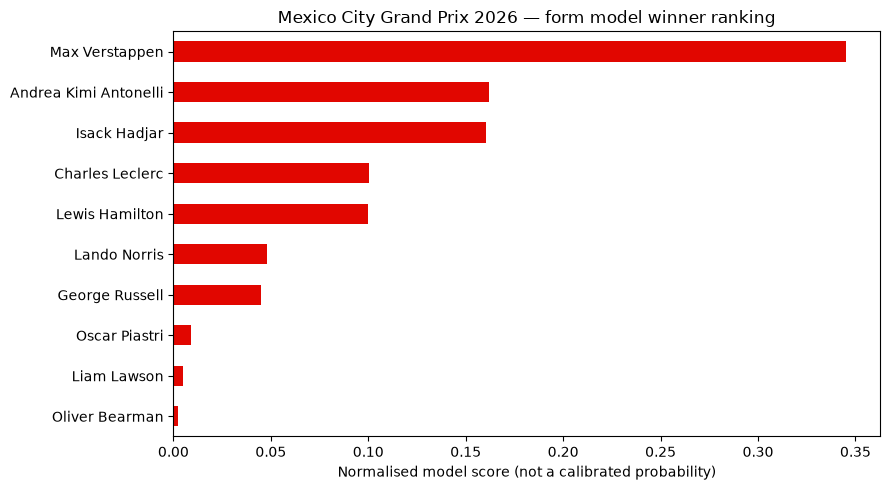

Mexico City Grand Prix 2026: top three picks (Form model)
Stage: pre-qualifying | Race day: 2026-11-01 | Results through: 2026-10-25
Entry list: last race’s grid — confirm any driver changes

1. Max Verstappen (Red Bull) — score 0.35
2. Andrea Kimi Antonelli (Mercedes) — score 0.16
3. Isack Hadjar (Red Bull) — score 0.16

Qualifying has not happened yet. Re-run after qualifying for the qualifying model.

Ranks reflect winner-model scores, not predicted podium positions.


In [7]:
#@title Run the prediction { display-mode: "form" }
form_model = new_model().fit(data[FORM_FEATURES], data.won)
quali_model = new_model().fit(data[QUALI_FEATURES], data.won)

def entry_frame(frame):
    out = frame[['driverId','constructorId','constructorName','givenName','familyName']].copy()
    out['driver'] = out.givenName + ' ' + out.familyName
    return out.rename(columns={'constructorName':'team'})[['driverId','constructorId','driver','team']]

if Path('entries.csv').exists():
    entries = pd.read_csv('entries.csv')
    assert {'driverId','constructorId','driver','team'} <= set(entries.columns)
    entry_source = 'entries.csv (user-supplied)'
elif len(target_quali):
    entries = entry_frame(target_quali)
    entry_source = 'this weekend’s qualifying line-up'
else:
    entries = entry_frame(history.loc[history.raceDate.eq(history.raceDate.max())])
    entry_source = 'last race’s grid — confirm any driver changes'
assert entries.driverId.is_unique and len(entries) >= 18
if 'quali_position' not in entries:
    entries['quali_position'] = entries.driverId.map(target_quali.set_index('driverId')['position'])

inputs = pd.DataFrame([features(r.driverId, r.constructorId, CIRCUIT_ID) for r in entries.itertuples()])
inputs = pd.concat([entries.reset_index(drop=True), inputs], axis=1)

def predict(model, cols):
    scores = model.predict_proba(inputs[cols])[:,1]
    out = inputs[['driverId','driver','team','quali_position']].copy()
    out['win_score'] = scores / scores.sum()
    return out.sort_values('win_score', ascending=False).reset_index(drop=True)

form_pred = predict(form_model, FORM_FEATURES)
quali_pred = None
if inputs.quali_position.notna().sum() >= 18:
    # A driver with no qualifying time starts from the back.
    inputs['quali_position'] = inputs.quali_position.fillna(len(inputs))
    quali_pred = predict(quali_model, QUALI_FEATURES)
use_quali = quali_pred is not None
predictions = quali_pred if use_quali else form_pred
model_name = 'Qualifying model' if use_quali else 'Form model'

ax = predictions.iloc[:10].sort_values('win_score').plot.barh(
    x='driver', y='win_score', legend=False, color='#E10600', figsize=(9,5))
ax.set_title(f'{RACE_NAME} {TARGET_YEAR} — {model_name.lower()} winner ranking')
ax.set_xlabel('Normalised model score (not a calibrated probability)'); ax.set_ylabel('')
plt.tight_layout(); plt.show()

print(f'{RACE_NAME} {TARGET_YEAR}: top three picks ({model_name})')
print(f'Stage: {STAGE} | Race day: {target_date.date()} | Results through: {history.raceDate.max().date()}')
print(f'Entry list: {entry_source}\n')
for rank, row in enumerate(predictions.head(3).itertuples(), start=1):
    grid = f', qualified P{int(row.quali_position)}' if use_quali else ''
    print(f'{rank}. {row.driver} ({row.team}{grid}) — score {row.win_score:.2f}')
if use_quali:
    pole = predictions.loc[predictions.quali_position.idxmin()]
    print(f'\nFor comparison, the "pole sitter wins" rule picks {pole.driver}. '
          f'On the {TEST_YEAR} test season it was right more often than either model (see section 4).')
else:
    print('\nQualifying has not happened yet. Re-run after qualifying for the qualifying model.')
print('\nRanks reflect winner-model scores, not predicted podium positions.')

## 7. After the race: prediction vs. result

This section fills in automatically once the race result has been published.

In [8]:
#@title Compare with the actual result { display-mode: "form" }
if STAGE != 'post-race':
    print('The race has not been run (or its result is not published yet). Re-run after the race.')
else:
    actual = target_race.assign(Driver=target_race.givenName + ' ' + target_race.familyName)
    finish = actual.set_index('driverId')['position']
    winner = actual.loc[actual.position.eq(1)].iloc[0]
    print(f"Winner: {winner.givenName} {winner.familyName} ({winner.constructorName})\n")
    summary = []
    for name, pred in [('Form model', form_pred), ('Qualifying model', quali_pred)]:
        if pred is None:
            continue
        rank_of_winner = int(pred.index[pred.driverId.eq(winner.driverId)][0]) + 1
        summary.append({'Model': name, 'Top pick': pred.driver.iloc[0],
                        'Top pick finished': f'P{int(finish.get(pred.driverId.iloc[0], np.nan))}',
                        'Winner was ranked': f'#{rank_of_winner}'})
    display(pd.DataFrame(summary).set_index('Model'))
    side = predictions.head(10).assign(Finished=lambda d: d.driverId.map(finish).map(lambda p: f'P{int(p)}'))
    side.index = side.index + 1
    display(side[['driver','team','win_score','Finished']]
            .rename(columns={'driver':'Driver','team':'Team','win_score':'Score'}).round(3))

The race has not been run (or its result is not published yet). Re-run after the race.
